# 09 A bigger model: more accurate, but does it fit on a kiosk?

**Why this notebook.** Our choice is a fine-tuned ResNet18 (notebook 08). The director may ask: "is there a
better model?" Bigger models exist. In notebook 07, a small CLIP (ViT-B/32) was already more accurate than
ResNet18 on validation. Here we take the **biggest CLIP of OpenAI at 224 x 224 pixels: CLIP ViT-L/14**. It is
a vision transformer with 24 layers, trained on 400 million images with their captions. We use it like
ResNet18 in notebook 05: frozen, with our linear head on top.

We ask two questions:

1. Is it more accurate than our fine-tuned ResNet18, on the same two tests?
2. Does it fit on a kiosk: time per photo, size of the file, need for a GPU?

At the end, we put the four models of our talk side by side, criterion by criterion: the random forest (our
classical baseline), our MLP, the fine-tuned ResNet18 and CLIP ViT-L/14.

**Rules, written before looking at any result.**

1. **The kiosk budget.** A visitor should get an answer in under 1 second. A kiosk CPU is about 4 times
   slower than our laptop, so a model must classify one photo in at most **250 ms on one laptop CPU thread**.
   The model file must stay under **200 MB** (small storage, updates over the museum network). No GPU.
2. CLIP ViT-L/14 gets the head recipe of notebook 05 (`train_head`, seeds 0, 1 and 2). Nothing is tuned on
   the tests.
3. The two tests (220 + 220 paintings) are used **once** for this model, as for the other models.
4. A model that breaks the budget cannot be chosen for the kiosk, whatever its accuracy.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import os
import time
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.flop_counter import FlopCounterMode

from museum_guide.baselines import hand_features, hand_features_batch, make_forest
from museum_guide.benchmark import cpu_threads, latency_ms, size_mb
from museum_guide.config import FAST_RUN, ROOT, set_seed
from museum_guide.data import channel_stats, class_names, load_images, load_metadata, make_split, standardise
from museum_guide.evaluation import (bootstrap_ci, confusion_matrix, load_results, paired_bootstrap, per_class_report,
                                     save_results)
from museum_guide.foundation import CLIP_LARGE, CLIP_NAME, CLIPEncoder, cached
from museum_guide.models import count_parameters
from museum_guide.plots import PALETTE, save_figure
from museum_guide.recipes import FINETUNE, MLP_REGULARISED, train_finetune, train_head, train_mlp
from museum_guide.training import make_loaders, predict

set_seed()
SEEDS = [0] if FAST_RUN else [0, 1, 2]
BUDGET_MS, BUDGET_MB, KIOSK_SLOWDOWN = 250, 200, 4  # rule 1, fixed before the run
# FAST_RUN=1 only checks that the code runs: it uses the small CLIP of notebook 07 instead of the big one.
BIG_NAME, BIG_TAG = (CLIP_NAME, "fast_clip_vit_b32") if FAST_RUN else (CLIP_LARGE, "clip_vit_l14")
TEST2_DIR = ROOT / "data" / "wikiart_test2"
RF, MLP = "random forest on hand-made features", "regularised MLP on pixels"
FT, BIG = "ResNet18 fine-tuned (layer4)", "CLIP ViT-L/14 + linear head"
PARTS = ("val", "test", "test2")

meta = load_metadata()
meta["split"] = make_split(meta)
classes = class_names(meta)
masks = {s: (meta["split"] == s).to_numpy() for s in ("train", "val", "test")}
meta2 = load_metadata(TEST2_DIR)
assert class_names(meta2) == classes, "same styles, same order"


def part(t, s):
    """The rows of t (one per painting of meta) that belong to the part s."""
    return t[torch.from_numpy(masks[s])]


x = {size: load_images(meta, size) for size in (224, 64, 32)}
x2 = {size: load_images(meta2, size, TEST2_DIR) for size in (224, 64, 32)}
y = {s: part(torch.tensor(meta["label_idx"].to_numpy()), s) for s in masks}
y["test2"] = torch.tensor(meta2["label_idx"].to_numpy())
truth = {p: y[p].numpy() for p in PARTS}
both_truth = np.concatenate([truth["test"], truth["test2"]])
print({s: int(m.sum()) for s, m in masks.items()}, "| test 2:", len(meta2), "| seeds", SEEDS, "| model", BIG_NAME)

{'train': 1061, 'val': 219, 'test': 220} | test 2: 220 | seeds [0, 1, 2] | model openai/clip-vit-large-patch14


C:\Users\benca\AppData\Local\Temp\ipykernel_53984\356479104.py:53: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  return t[torch.from_numpy(masks[s])]


## 1. CLIP ViT-L/14 turns each painting into 768 numbers

**What we do.** We download CLIP ViT-L/14 (about 1.7 GB) and keep it frozen. Its image part turns each
painting into 768 numbers, once, for our 1 500 paintings and the 220 paintings of test 2 (saved in
`data/cache`). We time it: it is also the main cost of a retraining when the collection changes.

In [2]:
big = CLIPEncoder(BIG_NAME)
F_all, seconds_per_image = cached(BIG_TAG, meta, lambda: big, x[224])
F2, _ = cached(f"{BIG_TAG}_test2", meta2, lambda: big, x2[224])
F = {s: part(F_all, s) for s in masks}
F["test2"] = F2
image_part = nn.ModuleList([big.clip.vision_model, big.clip.visual_projection])  # what a kiosk needs
params_image, params_total = count_parameters(image_part) / 1e6, count_parameters(big.clip) / 1e6
print(f"features: {tuple(F_all.shape)}, {seconds_per_image:.3f} s per painting (batches of 32, all CPU threads)")
print(f"parameters: {params_total:.0f} M in all, {params_image:.0f} M in the image part")

features: (1500, 768), 2.312 s per painting (batches of 32, all CPU threads)
parameters: 428 M in all, 304 M in the image part


**What we see.** Each painting becomes 768 numbers. CLIP ViT-L/14 has **428 million weights**, 304 million of
them in its image part, against 11 million for ResNet18. It needed **2.3 seconds per painting** with all the CPU
threads, so almost one hour for our 1 500 paintings. ResNet18 needed 15 ms per painting (notebook 05).

## 2. Our linear head on top, on validation

**What we do.** The head recipe of notebook 05 (`train_head`: standardisation, then one `nn.Linear` from the
768 numbers to the 5 styles, AdamW, early stopping), with seeds 0, 1 and 2. We compare its validation accuracy
with ResNet18 (notebook 05) and with the small CLIP (notebook 07), on the same 219 paintings.

In [3]:
head_runs, heads = [], []
for seed in SEEDS:
    t0 = time.perf_counter()
    head, _ = train_head(F["train"], y["train"], F["val"], y["val"], seed=seed)
    seconds = time.perf_counter() - t0
    heads.append(head)
    val_pred = predict(head, make_loaders(F["val"], y["val"], F["val"], y["val"]).val)[0].argmax(dim=1)
    head_runs.append({"seed": seed, "val_acc": (val_pred == y["val"]).float().mean().item(), "seconds": seconds,
                      "trained_parameters": count_parameters(head)})
head_runs = pd.DataFrame(head_runs)
d05, d07 = load_results("05_resnet"), load_results("07_transformers")
val_table = pd.Series({
    "ResNet18 frozen + linear head (notebook 05)": next(h["val_acc"] for h in d05["heads"] if h["head"] == "linear probe"),
    "ResNet18 fine-tuned (notebook 05)": np.mean([r["val_acc"] for r in d05["finetune_runs"]]),
    "CLIP ViT-B/32 + linear head (notebook 07)": next(r["val_acc"] for r in d07["probe_table"] if r["model"].startswith("CLIP")),
    "CLIP ViT-L/14 + linear head (this notebook)": head_runs["val_acc"].mean(),
}, name="validation accuracy")
print(head_runs.round(4).to_string(index=False))
val_table.round(3)

 seed  val_acc  seconds  trained_parameters
    0   0.9635   1.6185                3845
    1   0.9635   3.6740                3845
    2   0.9635   1.1979                3845


ResNet18 frozen + linear head (notebook 05)    0.881
ResNet18 fine-tuned (notebook 05)              0.854
CLIP ViT-B/32 + linear head (notebook 07)      0.947
CLIP ViT-L/14 + linear head (this notebook)    0.963
Name: validation accuracy, dtype: float64

**What we see.** CLIP ViT-L/14 reaches **96.3 %** on validation, with the same score for the 3 seeds (the
features are fixed, and the 3 heads end with the same predictions). It is the best model of the project:

- 8.2 points above the frozen ResNet18 (88.1 %) and 11.0 points above the fine-tuned one (85.4 %);
- 1.7 points above the small CLIP of notebook 07 (94.7 %): the bigger CLIP is better again.

## 3. The two tests, used once

**What we do.** The heads predict the 220 paintings of test 1 and the 220 new paintings of test 2 (new
painters, notebook 08). As in notebook 08: the mean accuracy over the 3 seeds, a 95 % bootstrap interval
(seed 0), and both tests together (440 paintings). The other models come from notebook 08.

In [4]:
big_preds = {p: [predict(hd, make_loaders(F[p], y[p], F[p], y[p]).val)[0].argmax(dim=1).numpy() for hd in heads]
             for p in PARTS}
big_row = {}
for p, label in (("test", "test 1"), ("test2", "test 2")):
    lo, hi = bootstrap_ci(big_preds[p][0] == truth[p])
    big_row.update({f"{label} acc": np.mean([(q == truth[p]).mean() for q in big_preds[p]]),
                    f"{label} low": lo, f"{label} high": hi})
both_big = [np.concatenate([big_preds["test"][k], big_preds["test2"][k]]) for k in range(len(heads))]
lo, hi = bootstrap_ci(both_big[0] == both_truth)
big_row.update({"both acc": np.mean([(q == both_truth).mean() for q in both_big]), "both low": lo, "both high": hi})

d08 = load_results("08_second_test")
tests = pd.DataFrame([{"model": r["model"], "test 1 acc": r["test 1 acc"], "test 2 acc": r["test 2 acc"],
                       "both acc": d08["both_tests_acc"][r["model"]]} for r in d08["table"]]
                     + [{"model": BIG, **{k: big_row[k] for k in ("test 1 acc", "test 2 acc", "both acc")}}]).set_index("model")
print({k: round(float(v), 4) for k, v in big_row.items()})
tests.round(3)

{'test 1 acc': 0.9742, 'test 1 low': 0.9545, 'test 1 high': 0.9955, 'test 2 acc': 0.9545, 'test 2 low': 0.9227, 'test 2 high': 0.9818, 'both acc': 0.9644, 'both low': 0.9477, 'both high': 0.9818}


,test 1 acc,test 2 acc,both acc
model,,,
regularised MLP on pixels,0.414,0.418,0.416
random forest on hand-made features,0.673,0.636,0.655
ResNet18 frozen + linear head,0.830,0.841,0.836
ResNet18 fine-tuned (layer4),0.879,0.877,0.878
CLIP ViT-L/14 + linear head,0.974,0.955,0.964


**What we see.** The lead holds on the two tests: **97.4 %** on test 1 (interval 95.5 to 99.5 %), **95.5 %** on
test 2 (92.3 to 98.2 %) and **96.4 %** on both tests (94.8 to 98.2 %). The fine-tuned ResNet18 gets 87.9 %,
87.7 % and 87.8 %. So about 1 visitor in 28 would get a wrong style with CLIP, against 1 in 8 with ResNet18.

## 4. The three other models, trained again (seed 0)

**What we do.** To compare the models on the same paintings, and to time them all in the same run, we train
again the random forest, our MLP and the fine-tuned ResNet18 with the recipes and settings of notebook 06
(seed 0). Their validation accuracy must be exactly the one of notebooks 03, 05 and 06: then they are the
same models.

In [5]:
t0 = time.perf_counter()
hand = hand_features_batch(x[64])
hand_seconds_per_image = (time.perf_counter() - t0) / len(meta)
hand2 = hand_features_batch(x2[64])
t0 = time.perf_counter()
forest = make_forest(**load_results("06_final")["classical_settings"][RF]).fit(hand[masks["train"]], y["train"].numpy())
rf_seconds = time.perf_counter() - t0

mean32, std32 = channel_stats(part(x[32], "train"))
mlp_in = {s: standardise(part(x[32], s), mean32, std32) for s in masks}
mlp_in["test2"] = standardise(x2[32], mean32, std32)
mlp, h = train_mlp(make_loaders(mlp_in["train"], y["train"], mlp_in["val"], y["val"], batch_size=64), seed=0,
                   **{k: v for k, v in MLP_REGULARISED.items() if k != "size"})
mlp_seconds = sum(h["epoch_time"])

img_in = {s: part(x[224], s) for s in masks}
img_in["test2"] = x2[224]
ft, h = train_finetune(make_loaders(img_in["train"], y["train"], img_in["val"], y["val"], batch_size=32, eval_batch_size=128),
                       seed=0, **(dict(FINETUNE, epochs=2) if FAST_RUN else FINETUNE))
ft_seconds = sum(h["epoch_time"])


def seed0_predictions(name):
    if name == RF:
        X = {"val": hand[masks["val"]], "test": hand[masks["test"]], "test2": hand2}
        return {p: forest.predict(X[p]) for p in PARTS}
    model, inputs = {MLP: (mlp, mlp_in), FT: (ft, img_in)}[name]
    return {p: predict(model, make_loaders(inputs[p], y[p], inputs[p], y[p], eval_batch_size=128).val)[0].argmax(dim=1).numpy()
            for p in PARTS}


seed0 = {n: seed0_predictions(n) for n in (RF, MLP, FT)}
seed0[BIG] = {p: big_preds[p][0] for p in PARTS}
before = {RF: max(load_results("06_final")["classical_tuning"][RF].values()),
          MLP: next(r["val_acc"] for r in load_results("03_monitoring")["tool_runs"] if r["tool"] == "all together" and r["seed"] == 0),
          FT: d05["finetune_runs"][0]["val_acc"]}
check = pd.DataFrame([{"model": n, "val_acc_now": (seed0[n]["val"] == truth["val"]).mean(), "val_acc_before": before[n]}
                      for n in (RF, MLP, FT)]).set_index("model")
check["same"] = (check["val_acc_now"] - check["val_acc_before"]).abs() < 1e-4
check.round(4)

,val_acc_now,val_acc_before,same
model,,,
random forest on hand-made features,0.6347,0.6347,True
regularised MLP on pixels,0.4612,0.4612,True
ResNet18 fine-tuned (layer4),0.8584,0.8584,True


**Is the lead of CLIP real?** The difference of accuracy on the same paintings (seed 0), with its bootstrap
interval, on each test and on both tests together. For comparison, the same for the fine-tuned ResNet18
against the random forest.

In [6]:
def correct(name, parts):
    return np.concatenate([seed0[name][p] == truth[p] for p in parts])


paired = pd.DataFrame([{"A": a, "B": b, "test": label, **paired_bootstrap(correct(a, ps), correct(b, ps))}
                       for a, b in ((BIG, FT), (FT, RF))
                       for label, ps in (("test 1", ["test"]), ("test 2", ["test2"]), ("test 1 + test 2 (440)", ["test", "test2"]))])
cm_big = confusion_matrix(torch.tensor(both_truth), torch.tensor(both_big[0]), 5)
per_class_big = per_class_report(cm_big, classes)
paired.round(3)

,A,B,test,diff,ci_low,ci_high,share_not_better
0,CLIP ViT-L/14 + linear head,ResNet18 fine-tuned (layer4),test 1,0.091,0.055,0.132,0.000
1,CLIP ViT-L/14 + linear head,ResNet18 fine-tuned (layer4),test 2,0.073,0.027,0.118,0.001
2,CLIP ViT-L/14 + linear head,ResNet18 fine-tuned (layer4),test 1 + test 2 (440),0.082,0.052,0.111,0.000
3,ResNet18 fine-tuned (layer4),random forest on hand-made features,test 1,0.214,0.141,0.286,0.000
4,ResNet18 fine-tuned (layer4),random forest on hand-made features,test 2,0.245,0.186,0.309,0.000
5,ResNet18 fine-tuned (layer4),random forest on hand-made features,test 1 + test 2 (440),0.230,0.182,0.277,0.000


In [7]:
per_class_big.round(3)

,recall,precision,f1,images
Baroque,0.988,0.977,0.983,86
Cubism,0.930,0.976,0.952,86
Impressionism,0.968,0.968,0.968,94
Pop_Art,0.954,0.922,0.938,87
Ukiyo_e,0.989,0.989,0.989,87


**What we see.**

- The three models trained again give exactly the validation accuracy of notebooks 03, 05 and 06 (column
  `same`): they are the same models.
- **CLIP's lead is real**: +9.1 points on test 1 (interval 5.5 to 13.2), +7.3 points on test 2 (2.7 to 11.8) and
  **+8.2 points on the 440 paintings (5.2 to 11.1)**. In none of the 5 000 redraws of the 440 paintings is CLIP
  not better.
- For comparison, the fine-tuned ResNet18 is 23.0 points above the random forest on the 440 paintings (18.2 to
  27.7).
- Per style (seed 0, 440 paintings), CLIP finds 93 % of the Cubist paintings and 95 % to 99 % of every other
  style.

## 5. The price on a kiosk

**What we do.** The measure of notebook 06, for the four models in the same run (times move by about 30 %
from one run to another on a laptop): one photo at a time, from a 224 x 224 colour image to the predicted
style, with the resizing and the features; the median over the runs, with 1 and 4 CPU threads. We also
measure:

- the **size of the model file** (for CLIP, only its image part and our head: a kiosk does not need its text
  part);
- the **compute per photo**: the number of operations, in billions (GFLOPs), counted by PyTorch
  (`FlopCounterMode`);
- the **retraining time** on this laptop when the collection changes: the features of the 1 061 training
  paintings (hand-made numbers for the forest, CLIP's 768 numbers), then the training itself.

In [8]:
class ImageClassifier(nn.Module):
    """What a kiosk would run: CLIP (only its image part is used) + our linear head."""

    def __init__(self, encoder, head):
        super().__init__()
        self.encoder, self.head = encoder, head

    def forward(self, x):
        return self.head(self.encoder(x))


def to_tensor(photo, size):
    photo = photo if photo.size == (size, size) else photo.resize((size, size), Image.Resampling.BILINEAR)
    return torch.from_numpy(np.asarray(photo).copy()).permute(2, 0, 1).unsqueeze(0)


def gflops(fn):
    """Billions of floating-point operations of one call of fn, counted by PyTorch."""
    with FlopCounterMode(display=False) as counter, torch.no_grad():
        fn()
    return counter.get_total_flops() / 1e9


big_model = ImageClassifier(big, heads[0]).eval()
mlp.eval()
ft.eval()
forest.set_params(n_jobs=1)  # one photo at a time: no parallel trees
photos = [Image.fromarray(img.permute(1, 2, 0).numpy()) for img in part(x[224], "test")[:20]]
pipelines = {
    RF: lambda p: forest.predict(hand_features(to_tensor(p, 64)[0])[None]),
    MLP: lambda p: mlp(standardise(to_tensor(p, 32), mean32, std32)).argmax(dim=1),
    FT: lambda p: ft(to_tensor(p, 224)).argmax(dim=1),
    BIG: lambda p: big_model(to_tensor(p, 224)).argmax(dim=1),
}
big_runs = 5 if FAST_RUN else 20  # CLIP is slow: fewer runs than the 50 of notebook 06
kiosk = []
with torch.no_grad():
    for name, fn in pipelines.items():
        row = {"model": name}
        for n in (1, 4):
            with cpu_threads(n):
                t = latency_ms(fn, photos, warmup=2, runs=big_runs) if name == BIG else latency_ms(fn, photos)
            row[f"ms_{n}_thread"], row[f"p95_ms_{n}_thread"] = t["median_ms"], t["p95_ms"]
        kiosk.append(row)
kiosk = pd.DataFrame(kiosk).set_index("model")

n_train = int(masks["train"].sum())
photo224 = to_tensor(photos[0], 224)
kiosk["size_mb"] = [size_mb(forest), size_mb(mlp), size_mb(ft), size_mb(nn.ModuleList([image_part, heads[0]]))]
kiosk["parameters_millions"] = [np.nan, count_parameters(mlp) / 1e6, count_parameters(ft) / 1e6,
                                params_image + count_parameters(heads[0]) / 1e6]
kiosk["gflops"] = [np.nan, gflops(lambda: mlp(standardise(to_tensor(photos[0], 32), mean32, std32))),
                   gflops(lambda: ft(photo224)), gflops(lambda: big_model(photo224))]
kiosk["retrain_seconds"] = [hand_seconds_per_image * n_train + rf_seconds, mlp_seconds, ft_seconds,
                            seconds_per_image * n_train + head_runs.loc[0, "seconds"]]
kiosk.round(2)

,ms_1_thread,p95_ms_1_thread,ms_4_thread,p95_ms_4_thread,size_mb,parameters_millions,gflops,retrain_seconds
model,,,,,,,,
random forest on hand-made features,67.20,98.27,73.27,102.77,25.85,NaN,NaN,5.25
regularised MLP on pixels,0.95,1.61,1.34,2.10,6.84,1.71,0.00,18.25
ResNet18 fine-tuned (layer4),121.43,156.08,53.94,63.46,44.80,11.18,3.63,204.94
CLIP ViT-L/14 + linear head,4576.22,5598.48,1946.28,2073.08,1216.03,303.97,155.53,2455.10


**What we see.**

- **Time per photo, one CPU thread**: 1.0 ms for the MLP, 67 ms for the random forest, 121 ms for the fine-tuned
  ResNet18 and **4.6 seconds for CLIP ViT-L/14, 38 times ResNet18**. With 4 threads: 54 ms for ResNet18 and
  1.9 s for CLIP.
- This run was slower than notebook 06 (ResNet18: 121 ms here, 53 ms there): the laptop was running on battery.
  The four models were timed in the same run, so the comparison between them is fair; the ratios are what to
  remember.
- **Model file**: 45 MB for ResNet18, **1.2 GB for CLIP's image part alone**, 27 times more.
- **Compute per photo**: 3.6 billion operations for ResNet18, **156 billion for CLIP**, 43 times more. The time
  follows the compute.
- **Retraining on this laptop**: 3.4 minutes for ResNet18, **41 minutes for CLIP** (2.3 s per training painting
  for its features, then 2 s for the head).

## 6. Every model, criterion by criterion

**What we do.** One table for the four models of our talk: the accuracy on the 440 test paintings (mean of
the seeds, notebooks 08 and 09), and the kiosk criteria of section 5, checked against the budget of rule 1.

In [9]:
order = [RF, MLP, FT, BIG]
recap = pd.DataFrame({
    "accuracy, 440 test paintings": tests.loc[order, "both acc"],
    "ms per photo, 1 thread": kiosk.loc[order, "ms_1_thread"],
    "seconds on a kiosk 4x slower": kiosk.loc[order, "ms_1_thread"] * KIOSK_SLOWDOWN / 1000,
    "model file (MB)": kiosk.loc[order, "size_mb"],
    "GFLOPs per photo": kiosk.loc[order, "gflops"],
    "retraining (minutes)": kiosk.loc[order, "retrain_seconds"] / 60,
})
recap["within the time budget"] = recap["ms per photo, 1 thread"] <= BUDGET_MS
recap["within the size budget"] = recap["model file (MB)"] <= BUDGET_MB
recap["fits the kiosk"] = recap["within the time budget"] & recap["within the size budget"]
recap.round(3)

,"accuracy, 440 test paintings","ms per photo, 1 thread",seconds on a kiosk 4x slower,model file (MB),GFLOPs per photo,retraining (minutes),within the time budget,within the size budget,fits the kiosk
model,,,,,,,,,
random forest on hand-made features,0.655,67.198,0.269,25.850,NaN,0.087,True,True,True
regularised MLP on pixels,0.416,0.952,0.004,6.841,0.003,0.304,True,True,True
ResNet18 fine-tuned (layer4),0.878,121.432,0.486,44.796,3.627,3.416,True,True,True
CLIP ViT-L/14 + linear head,0.964,4576.220,18.305,1216.028,155.533,40.918,False,False,False


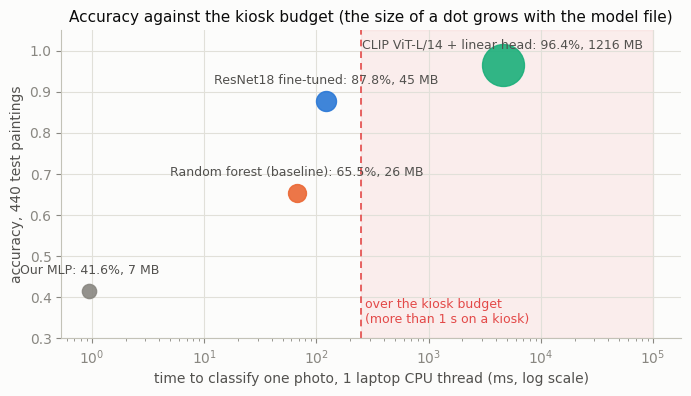

In [10]:
labels = {RF: "Random forest (baseline)", MLP: "Our MLP", FT: "ResNet18 fine-tuned", BIG: "CLIP ViT-L/14 + linear head"}
colors = {RF: PALETTE[1], MLP: "#898781", FT: PALETTE[0], BIG: PALETTE[2]}
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(BUDGET_MS, 10 ** np.ceil(np.log10(recap["ms per photo, 1 thread"].max() * 3)), color="#e34948", alpha=0.08, zorder=0)
ax.axvline(BUDGET_MS, color="#e34948", linewidth=1.2, linestyle=(0, (4, 3)))
ax.text(BUDGET_MS * 1.08, 0.33, "over the kiosk budget\n(more than 1 s on a kiosk)", color="#e34948", fontsize=9, va="bottom")
for n in order:
    r = recap.loc[n]
    ax.scatter(r["ms per photo, 1 thread"], r["accuracy, 440 test paintings"], s=40 + 2.5 * np.sqrt(r["model file (MB)"]) * 10,
               color=colors[n], zorder=3, alpha=0.9)
    ax.annotate(f"{labels[n]}: {r['accuracy, 440 test paintings']:.1%}, {r['model file (MB)']:.0f} MB",
                (r["ms per photo, 1 thread"], r["accuracy, 440 test paintings"]), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=9, color="#52514e")
ax.set_xscale("log")
ax.set_ylim(0.3, 1.05)
ax.set_xlabel("time to classify one photo, 1 laptop CPU thread (ms, log scale)")
ax.set_ylabel("accuracy, 440 test paintings")
ax.set_title("Accuracy against the kiosk budget (the size of a dot grows with the model file)")
save_figure(fig, "09_recap")
plt.show()

In [11]:
save_results("09_big_model", {
    "budget": {"ms_1_thread": BUDGET_MS, "size_mb": BUDGET_MB, "kiosk_slowdown": KIOSK_SLOWDOWN},
    "model": {"name": BIG_NAME, "features": int(F_all.shape[1]), "parameters_millions_total": params_total,
              "parameters_millions_image": params_image, "feature_seconds_per_image_batch32": seconds_per_image},
    "head_runs": head_runs.to_dict(orient="records"),
    "validation": val_table.to_dict(),
    "tests": big_row,
    "tests_all_models": tests.reset_index().to_dict(orient="records"),
    "reproducibility": check.reset_index().to_dict(orient="records"),
    "paired": paired.to_dict(orient="records"),
    "per_class_both_tests_seed0": per_class_big.reset_index(names="style").to_dict(orient="records"),
    "kiosk": kiosk.reset_index().to_dict(orient="records"),
    "recap": recap.reset_index().to_dict(orient="records"),
    "cpu_threads_available": torch.get_num_threads(),
})

WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/09_big_model.json')

## What we learned

- **A bigger model is more accurate.** CLIP ViT-L/14, frozen with our linear head, reaches **96.4 %** on the 440
  test paintings, 8.2 points above the fine-tuned ResNet18 (interval 5.2 to 11.1): not luck.
- **But it does not fit on a kiosk.** On a kiosk 4 times slower than this laptop, it would need about **18 seconds
  per photo**, for a budget of 1 second, and its file is 1.2 GB, for a budget of 200 MB. To answer in under a
  second, it would need a GPU or a much bigger computer. We have no GPU, so we give no GPU number.
- **The recap by criteria.** The random forest and our MLP fit the kiosk but are not accurate enough (65.5 % and
  41.6 %). CLIP is the most accurate but breaks the budget. **The fine-tuned ResNet18 is the only model that is
  both accurate (87.8 %) and within the budget** (121 ms here, 45 MB, retrained in a few minutes, no GPU).
- **Caution.** CLIP learned from 400 million Internet images: it has very probably seen WikiArt paintings with
  captions that name their style, so part of its score may be memory. If the kiosks ever get a GPU, test CLIP on
  real kiosk photos first.